# 03 v3 - Live first-innings score prediction

**Why this notebook exists.** Notebook 02 predicted the first-innings total *before the match* and plateaued at MAE ~27 runs
(the ceiling of those inputs). v1 changed the question: predict the final total **from the match state at the end of each over**.
v2 fixed the venue feature, added phase features, stage-wise switching, bootstrap CIs and a better range.
v3 is a small clean-up round based on the v2 results. It adds no new modelling ideas.

## Where v2 ended (your real run)

| What | v2 result |
|------|-----------|
| Pre-match MAE: league avg / v1 venue / v2 era-adjusted venue | 26.01 / 27.51 / 25.59 (v2 vs v1 venue: gain 1.92 runs, CI [0.57, 3.30]) |
| Mean MAE over overs 1-19, validation 2021-24 | Stage-wise 16.53, Ridge 16.63, Ridge v1 features 16.72, Par 17.51, GB 17.71 |
| Ridge v2 vs v1 features | gain 0.10 runs, CI [-0.02, 0.22] -> noise overall; real only in late overs |
| Stage-wise cut at over 16 | **not supported by validation**: Par beat Ridge clearly only at over 19 (gain 2.20, CI [1.60, 2.80]) |
| 80% range coverage, 2 calibration seasons | 77.8% validation, 76.8% holdout (target 80%) |
| Holdout 2025-26 | looked at for v1 *and* v2 decisions -> no longer a clean test |

## What v3 changes

| # | Change | Why |
|---|--------|-----|
| 1 | `STAGE_CUT = 18` (Par table only for over 19) | The only cut that validation data supports |
| 2 | Interval **width scale** and number of calibration seasons chosen on validation data (smallest range that reaches 80% pooled coverage) | v2 coverage was still 77-78% |
| 3 | **2025 moves into the validation folds** (folds 2021-25); the untouched holdout is **2026 only** | The 2025-26 holdout was already used for decisions |

Because the holdout is now one season (a few dozen matches), expect wide bootstrap intervals there. Treat the holdout as a sanity check,
not as a precise score.

## Experiment log (notebook 02, kept for reference)

| # | Technique | Result (MAE, runs) | Verdict |
|---|-----------|-------------------|---------|
| 1 | Fixed train-mean baseline (80/20 chrono split) | 37.1 | Weak: ignores scoring era |
| 2 | Rolling previous-3-seasons mean | 31.5 | Big jump, from *era* info only |
| 3 | Ridge (season, venue, city, teams, toss) | 31.7 | No gain over #2 |
| 4 | Random Forest, same features | 31.2 | Tiny gain |
| 5 | RF + team batting form | 32.7 | **Worse**: noise |
| 6 | Recency-weighted mean (decay 0.990-0.998) | 33.1-35.7 | Worse than rolling windows: too much old history |
| 7 | RF + league scoring trend | 32.3 | Worse |
| 8 | Season-only RF | 30.6 | Season alone beats full RF |
| 9 | Linear season trend | 32.4 | Cannot follow the 2023+ jump |
| 10 | Rolling last-30-match mean | 30.3 | Best simple model |
| 11 | Date-safe rolling baseline (same-day leak fix) | 30.3 | Correct fix, same score |
| 12 | RF + team/venue history | 32.0 | Worse |
| 13 | HistGradientBoosting | 30.6 | ~ baseline |
| 14 | Rolling-origin folds 2021-24 + 2025-26 holdout | - | **Right validation design** |
| 15 | Recent-30 vs 70/30 blend with previous seasons | 27.5 / 27.2 | Blend wins 1 of 4 seasons |
| 16 | Venue-name standardisation (60 -> 49 venues) | 27.3 -> 27.0 | Correct, small gain |
| 17 | Champion RF (standardised base) | 27.0 | Beats recent-30 (27.5) by 0.5 run |
| 18 | + team form / team history / bowling history / league environment | 27.5-29.3 | All worse than #17 |
| 19 | Gradient Boosting (huber) | 26.9 | Same as RF within noise |
| 20 | Error analysis | - | Predictions squeezed to 146-203 vs actual 68-287 |

> Rows 1-13 were scored on one 80/20 split (MAE ~30-37); rows 14+ use rolling folds validated on 2021-24 (MAE ~27).
> The drop is mostly an easier test set, not a better model. Compare numbers only inside the same block.

## Diagnosis (unchanged) - why pre-match predictions never "got right"
1. **Ceiling**: pre-match score std ~ 31-38, so MAE ~ 25-27 is what a good pre-match model looks like.
2. **Regression to the mean**: prediction std 2-11 vs actual 29-39.
3. **Regime shift**: ~160-172 (2017-22) -> 183 (2023) -> 190 (2024); trees on `season` cannot extrapolate.
4. **Tiny validation folds**: 60-74 matches, MAE standard error ~2-3 runs.
5. **Redundant / weak features**: `batting_team_won_toss` == `toss_decision == "bat"`; `city` duplicates `venue`; ~120 one-hot columns for ~1,000 rows.
6. **Unused ball-by-ball data.**

## Rules kept from v1/v2
* One row per (match, end-of-over k), k = 1..19; target = **remaining runs**; prediction = runs so far + remaining.
* Pre-match context uses only matches with an earlier date.
* Season-based rolling-origin validation (2021-25); **2026 is evaluated once, at the end**.

In [3]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# Same convention as notebooks 01/02: notebook lives in /notebooks, data in /data/raw
PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse first innings ball-by-ball

In [4]:
# 'retired hurt' is not a lost wicket (the batter may return), so it is not counted.
NOT_A_WICKET = {"retired hurt", "retired not out"}


def iter_raw_deliveries(innings_data):
    # Yield raw delivery dicts for both Cricsheet layouts.
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d):
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    return {
        "total": runs.get("total", 0) or 0,
        "batter": runs.get("batter", runs.get("batsman", 0)) or 0,
        "wide": extras.get("wides", 0) or 0,
        "noball": extras.get("noballs", 0) or 0,
        "wickets": sum(1 for w in wk if w.get("kind") not in NOT_A_WICKET),
    }


def over_end_states(deliveries):
    # {k: (runs, wickets, boundaries)} measured when the 6th LEGAL ball of over k is bowled.
    # Wides and no-balls are not legal balls, so they never close an over.
    runs = wkts = bnd = legal = 0
    states = {}
    for d in deliveries:
        runs += d["total"]
        wkts += d["wickets"]
        if d["batter"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0 and d["noball"] == 0:
            legal += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd)
    return states, runs, wkts, legal


def load_first_innings(raw_dir):
    rows, states_by_match, errors = [], {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            first = None
            for entry in match.get("innings", []):
                name, data = next(iter(entry.items()))
                if name == "1st innings":              # skips 2nd innings and Super Overs
                    first = data
                    break
            if first is None:
                continue
            deliveries = [parse_delivery(d) for d in iter_raw_deliveries(first)]
            states, final, wkts, legal = over_end_states(deliveries)
            rows.append({
                "match_id": path.stem,
                "date": pd.to_datetime(str(info["dates"][0])),
                "venue_raw": info.get("venue"),
                "batting_team": first.get("team"),
                "scheduled_overs": info.get("overs", 20),
                "final_score": final,
                "final_wickets": wkts,
                "legal_balls": legal,
            })
            states_by_match[path.stem] = states
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), states_by_match, errors


matches, states_by_match, load_errors = load_first_innings(RAW_DATA_DIR)
print("Matches parsed :", len(matches))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243
Load errors    : 0 []


In [5]:
# Keep only complete 20-over first innings (or all out). Rain-shortened innings have a different target.
matches["complete"] = (
    (matches["scheduled_overs"] == 20)
    & ((matches["legal_balls"] >= 120) | (matches["final_wickets"] >= 10))
)
print("Dropped (shortened / curtailed first innings):", int((~matches["complete"]).sum()))
matches = matches[matches["complete"]].drop(columns="complete").reset_index(drop=True)
matches["season"] = matches["date"].dt.year


# --- venue names: strip ', City' suffix + known renames (extend the alias dict if you spot more) ---
VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("Venue labels: raw %d -> standardised %d" % (matches["venue_raw"].nunique(), matches["venue"].nunique()))
print(matches["venue"].value_counts().head(8).to_string())
print("\nVenues with < 5 matches (check these for missed aliases):")
print(matches["venue"].value_counts().loc[lambda s: s < 5].to_string())

Dropped (shortened / curtailed first innings): 28
Venue labels: raw 60 -> standardised 36
venue
Wankhede Stadium                                132
Eden Gardens                                    102
Arun Jaitley Stadium                            101
MA Chidambaram Stadium                           98
M Chinnaswamy Stadium                            97
Rajiv Gandhi International Stadium               89
Sawai Mansingh Stadium                           66
Punjab Cricket Association IS Bindra Stadium     60

Venues with < 5 matches (check these for missed aliases):
venue
Green Park                              4
Nehru Stadium                           4
Buffalo Park                            3
De Beers Diamond Oval                   3
Vidarbha Cricket Association Stadium    3
OUTsurance Oval                         2


## 2. Leak-safe pre-match context (v2: era-adjusted venue effect)
All values use only matches with `date <` the current match date (same-day matches never see each other).

* `league_recent` = mean of the last 60 earlier totals (the scoring era "right now").
* `excess` of a past match = its score minus the `league_recent` **that existed before that match**.
  A 170 in 2012 (league ~ 150) is +20; a 170 in 2024 (league ~ 190) is -20.
* `venue_effect` = sum of the venue's past `excess` / (matches there + 5). The "+5" shrinks small samples toward 0.
* `venue_prior` (v1 definition, raw venue totals shrunk to the league average) is kept so v1 and v2 can be compared.

In [6]:
def add_prior_context(df, league_window=60, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()
    n_all = len(m)

    # pass 1: scoring era at the time of every match (strictly earlier dates only)
    league = np.empty(n_all)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        recent = totals[prior][-league_window:]
        league[i] = recent.mean() if len(recent) >= 5 else fallback
    excess = totals - league            # how far this match was above the era average of ITS OWN time

    # pass 2: venue statistics from earlier matches
    venue_prior, venue_effect, venue_n = np.empty(n_all), np.empty(n_all), np.empty(n_all, dtype=int)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        sv = prior[venues[prior] == venues[i]]
        n = len(sv)
        venue_n[i] = n
        venue_prior[i] = (totals[sv].sum() + venue_shrink * league[i]) / (n + venue_shrink)    # v1
        venue_effect[i] = excess[sv].sum() / (n + venue_shrink)                                # v2
    m["league_recent"], m["excess"] = league, excess
    m["venue_prior"], m["venue_effect"], m["venue_n"] = venue_prior, venue_effect, venue_n
    return m


matches = add_prior_context(matches)
print(matches[["venue", "final_score", "league_recent", "venue_prior", "venue_effect", "venue_n"]].tail(5).round(1).to_string())

# Sanity view: venues with a decent sample, using ALL matches (descriptive only, not used for training)
ve = (matches.groupby("venue").agg(n=("excess", "size"), raw_avg=("final_score", "mean"), era_adj_effect=("excess", "mean"))
      .query("n >= 15").sort_values("era_adj_effect"))
print("\nVenues with >= 15 matches: raw average vs era-adjusted effect (runs above the era average)")
ve.round(1)

                                                        venue  final_score  league_recent  venue_prior  venue_effect  venue_n
1210                                             Eden Gardens          203          196.2        172.7           2.5      101
1211             Himachal Pradesh Cricket Association Stadium          254          195.8        192.5          14.9       17
1212  Maharaja Yadavindra Singh International Cricket Stadium          243          197.3        185.1          -6.3       15
1213  Maharaja Yadavindra Singh International Cricket Stadium          214          197.9        188.0          -3.8       16
1214                                    Narendra Modi Stadium          155          198.8        182.7           3.2       52

Venues with >= 15 matches: raw average vs era-adjusted effect (runs above the era average)


,n,raw_avg,era_adj_effect
venue,,,
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium,27,175.4,-11.8
Zayed Cricket Stadium,37,158.9,-7.8
Kingsmead,15,152.0,-6.4
Sharjah Cricket Stadium,28,159.0,-5.9
MA Chidambaram Stadium,98,165.6,-4.7
Maharaja Yadavindra Singh International Cricket Stadium,17,186.6,-3.8
Dubai International Cricket Stadium,46,163.8,-2.7
Rajiv Gandhi International Stadium,89,168.7,-2.2
Dr DY Patil Sports Academy,36,161.0,-2.2


## 3. One row per (match, end of over k)
Features use only balls already bowled. Target = runs still to come.
v2 adds phase features: powerplay runs/wickets (overs 1-6, carried forward), last-3-overs run rate,
a phase flag (0 = overs 1-6, 1 = overs 7-15, 2 = overs 16+) and wickets-in-hand x run-rate.

In [7]:
TOTAL_OVERS = 20


def snapshot_features(states, k):
    # Features at the end of over k. Reads states[j] for j <= k ONLY (checked by the leak test below).
    def at(j):
        return states[j] if j >= 1 else (0, 0, 0)
    runs, wkts, bnd = states[k]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = states[min(k, 6)]
    return {
        "over": k,
        "overs_left": TOTAL_OVERS - k,
        "runs": runs,
        "wickets": wkts,
        "wickets_in_hand": 10 - wkts,
        "run_rate": runs / k,
        "runs_last5": runs - r5,
        "wkts_last5": wkts - w5,
        "rr_last5": (runs - r5) / min(k, 5),
        "boundaries": bnd,
        # ---- v2 phase features ----
        "pp_runs": pp_runs,                          # powerplay total (partial while k < 6)
        "pp_wkts": pp_wkts,
        "rr_last3": (runs - r3) / min(k, 3),
        "phase": 0 if k <= 6 else (1 if k <= 15 else 2),
        "hand_x_rr": (10 - wkts) * runs / k,
    }


def add_linear_terms(df):
    # linear-friendly terms: Ridge cannot multiply features by itself
    df = df.copy()
    L = df["overs_left"]
    df["crr_remaining"] = df["run_rate"] * L
    df["form_remaining"] = df["rr_last5"] * L
    df["form3_remaining"] = df["rr_last3"] * L
    df["league_remaining"] = df["league_recent"] / TOTAL_OVERS * L
    df["venue_remaining"] = df["venue_effect"] / TOTAL_OVERS * L          # v2 (era-adjusted)
    df["venue_remaining_v1"] = df["venue_prior"] / TOTAL_OVERS * L        # v1 (raw shrunk average)
    df["hand_x_left"] = df["wickets_in_hand"] * L
    df["hand_x_crr_rem"] = df["wickets_in_hand"] * df["crr_remaining"] / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


def build_snapshots(matches, states_by_match, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = states_by_match[r.match_id]
        for k in overs:
            if k not in states:            # innings ended (all out) before this over
                continue
            f = snapshot_features(states, k)
            f.update(match_id=r.match_id, date=r.date, season=r.season,
                     venue_prior=r.venue_prior, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     league_recent=r.league_recent, final_score=r.final_score)
            rows.append(f)
    snap = pd.DataFrame(rows)
    snap["remaining"] = snap["final_score"] - snap["runs"]
    return add_linear_terms(snap)


snap = build_snapshots(matches, states_by_match)
print("Snapshot rows:", len(snap), "| matches:", snap["match_id"].nunique())
snap.drop(columns=["date"]).head(3).round(2)

Snapshot rows: 23013 | matches: 1215


,over,overs_left,runs,wickets,wickets_in_hand,run_rate,runs_last5,wkts_last5,rr_last5,boundaries,...,crr_remaining,form_remaining,form3_remaining,league_remaining,venue_remaining,venue_remaining_v1,hand_x_left,hand_x_crr_rem,phase_mid,phase_death
0,1,19,3,0,10,3.0,3,0,3.0,0,...,57.0,57.0,57.0,152.0,0.0,152.0,190,57.0,0,0
1,2,18,21,0,10,10.5,21,0,10.5,4,...,189.0,189.0,189.0,144.0,0.0,144.0,180,189.0,0,0
2,3,17,27,0,10,9.0,27,0,9.0,5,...,153.0,153.0,153.0,136.0,0.0,136.0,170,153.0,0,0


## 4. Leak tests (these must pass before any model is trusted)

In [8]:
rng = np.random.default_rng(0)

# (a) snapshot features at over k must not change if every later over is deleted (includes the new phase features)
ids = rng.choice(matches["match_id"].to_numpy(), size=min(40, len(matches)), replace=False)
for mid in ids:
    states = states_by_match[mid]
    for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
        full = snapshot_features(states, k)
        cut = snapshot_features({j: v for j, v in states.items() if j <= k}, k)
        assert full == cut, ("future information used", mid, k)
print("OK: over-k features (incl. phase features) use only balls up to over k")

# (b) pre-match context (league, venue_prior, era-adjusted venue_effect) must not change if the
#     current and all later matches are corrupted
probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
corrupt.loc[corrupt["date"] >= probe["date"], "final_score"] = 999
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
for col in ("league_recent", "venue_prior", "venue_effect"):
    assert np.isclose(a[col], b[col]), col
print("OK: league / venue / era-adjusted venue context uses only earlier dates")

# (b2) same-day matches must not see each other
day = matches.groupby("date").filter(lambda g: len(g) > 1)
if len(day):
    d0 = day["date"].iloc[0]
    same = add_prior_context(matches).query("date == @d0")
    assert same["league_recent"].nunique() == 1
    print("OK: matches on the same day share the same league_recent")

# (c) totals rebuilt from the over-by-over states are consistent with the final score
bad = [mid for mid in states_by_match if mid in set(matches["match_id"])
       and states_by_match[mid].get(19, (0,))[0] > matches.set_index("match_id").loc[mid, "final_score"]]
assert not bad, bad[:5]
print("OK: runs after over 19 never exceed the final score")

OK: over-k features (incl. phase features) use only balls up to over k
OK: league / venue / era-adjusted venue context uses only earlier dates
OK: matches on the same day share the same league_recent
OK: runs after over 19 never exceed the final score


## 5. Models and validation
Rolling-origin by season (validate 2021, 2022, 2023, 2024, 2025). 2026 stays untouched until section 7.

Models: naive run-rate x 20 | Par table | **Ridge** (v2 features) | **Ridge V1 features** (ablation: same Ridge, v1 feature set) |
Gradient boosting | **Stage-wise** (Ridge for overs 1-`STAGE_CUT`, Par table after).

In [9]:
RAW_FEATS_V1 = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate",
                "runs_last5", "wkts_last5", "rr_last5", "boundaries",
                "venue_prior", "venue_n", "league_recent"]
LIN_FEATS_V1 = RAW_FEATS_V1 + ["crr_remaining", "form_remaining", "league_remaining",
                               "venue_remaining_v1", "hand_x_left"]

RAW_FEATS = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate",
             "runs_last5", "wkts_last5", "rr_last5", "boundaries",
             "venue_effect", "venue_n", "league_recent",
             "pp_runs", "pp_wkts", "rr_last3", "phase", "hand_x_rr"]
LIN_FEATS = RAW_FEATS + ["crr_remaining", "form_remaining", "form3_remaining", "league_remaining",
                         "venue_remaining", "hand_x_left", "hand_x_crr_rem", "phase_mid", "phase_death"]
STAGE_CUT = 18          # Ridge for overs 1..18, Par table for over 19 (the only late over where validation clearly supports Par; see 5b)


class CRRProjection:
    # Naive projection: current run rate x 20 overs.
    name = "Run-rate x 20 (naive)"
    def fit(self, tr): return self
    def predict_final(self, df): return df["run_rate"].to_numpy() * TOTAL_OVERS


class ParByOverWickets:
    # Average 'runs still to come' from training data, given (over, wickets lost).
    name = "Par table (over, wickets)"
    def fit(self, tr):
        t = tr.assign(w=tr["wickets"].clip(upper=6))
        self.tab = t.groupby(["over", "w"])["remaining"].mean()
        self.by_over = t.groupby("over")["remaining"].mean()
        return self
    def predict_final(self, df):
        w = df["wickets"].clip(upper=6)
        rem = [self.tab.get((o, ww), self.by_over.get(o, np.nan)) for o, ww in zip(df["over"], w)]
        return df["runs"].to_numpy() + np.array(rem)


class RidgeRemaining:
    name = "Ridge"
    feats = LIN_FEATS
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        self.m.fit(tr[self.feats], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[self.feats])


class RidgeV1Features(RidgeRemaining):
    name = "Ridge (v1 features)"
    feats = LIN_FEATS_V1


def make_hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=60, l2_regularization=1.0, random_state=0, **kw)

class HGBRemaining:
    name = "Gradient boosting"
    def fit(self, tr):
        self.m = make_hgb().fit(tr[RAW_FEATS], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[RAW_FEATS])


class StageWise:
    name = "Stage-wise (Ridge + Par)"
    def fit(self, tr):
        self.early = RidgeRemaining().fit(tr)
        self.late = ParByOverWickets().fit(tr)
        return self
    def predict_final(self, df):
        is_late = (df["over"] > STAGE_CUT).to_numpy()
        return np.where(is_late, self.late.predict_final(df), self.early.predict_final(df))


MODELS = [CRRProjection, ParByOverWickets, RidgeRemaining, RidgeV1Features, HGBRemaining, StageWise]
NAIVE, PAR, RIDGE, RIDGE_V1, GB, STAGE = (M.name for M in MODELS)

FOLDS = [{"train_through": y - 1, "validate": y} for y in (2021, 2022, 2023, 2024, 2025)]
FOLDS = [f for f in FOLDS if (snap["season"] == f["validate"]).any()]   # skip folds with no data
HOLDOUT_START = 2026
dev = snap[snap["season"] < HOLDOUT_START]
holdout = snap[snap["season"] >= HOLDOUT_START]
print("Dev rows:", len(dev), "| holdout rows:", len(holdout), "| folds:", [f["validate"] for f in FOLDS])

Dev rows: 21668 | holdout rows: 1345 | folds: [2021, 2022, 2023, 2024, 2025]


In [10]:
def run_folds(folds, data):
    out = []
    for f in folds:
        tr = data[data["season"] <= f["train_through"]]
        va = data[data["season"] == f["validate"]]
        for M in MODELS:
            model = M().fit(tr)
            pred = model.predict_final(va)
            out.append(va[["match_id", "over", "final_score"]].assign(
                model=model.name, pred=pred, fold=f["validate"]))
    return pd.concat(out, ignore_index=True)


dev_preds = run_folds(FOLDS, dev)
dev_preds["abs_err"] = (dev_preds["pred"] - dev_preds["final_score"]).abs()

CHECKPOINTS = [1, 3, 6, 10, 15, 18]
by_over = dev_preds.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
print("Pooled validation MAE (runs) by over, folds 2021-2025")
by_over.loc[CHECKPOINTS].round(1)

Pooled validation MAE (runs) by over, folds 2021-2025


model,Gradient boosting,"Par table (over, wickets)",Ridge,Ridge (v1 features),Run-rate x 20 (naive),Stage-wise (Ridge + Par)
over,,,,,,
1,26.9,29.0,26.0,26.2,74.4,26.0
3,25.7,27.1,24.4,24.3,43.6,24.4
6,22.1,23.0,21.0,20.8,28.9,21.0
10,17.5,17.9,16.9,16.9,21.6,16.9
15,11.4,11.2,10.4,10.6,14.4,10.4
18,8.1,7.0,7.2,7.7,8.2,7.2


### 5a. Bootstrap tools (match-level)
Every comparison below is **paired by match**: for each match we take `error(reference) - error(challenger)`
(positive = challenger is better), then resample *matches* 2,000 times. Resampling matches (not rows) matters because
the 19 snapshots of one match are not independent. If the 95% interval includes 0 the verdict is **noise**.

In [11]:
PRE = "Pre-match (league avg)"


def per_match_table(preds, matches_df, over=None):
    # one row per match; columns = models (+ the pre-match baseline). over=None -> average over overs 1-19
    t = preds if over is None else preds[preds["over"] == over]
    t = t.pivot_table(index="match_id", columns="model", values="abs_err", aggfunc="mean")
    ref = matches_df.set_index("match_id")
    t[PRE] = (ref["final_score"] - ref["league_recent"]).abs().reindex(t.index)
    return t.dropna()


def boot_mean_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi


PAIRS = [   # (challenger, reference)
    (RIDGE, RIDGE_V1),     # did the phase features + era-adjusted venue help?
    (STAGE, RIDGE),        # did the stage-wise switch help?
    (RIDGE, PAR),          # is Ridge better than a plain lookup table?
    (GB, RIDGE),           # is boosting better than Ridge?
    (RIDGE, PRE),          # how much does the live state add over the pre-match guess?
]


def compare(preds, matches_df, pairs=PAIRS, overs=CHECKPOINTS + ["ALL"]):
    rows = []
    for o in overs:
        t = per_match_table(preds, matches_df, None if o == "ALL" else o)
        for ch, ref in pairs:
            if ch not in t or ref not in t:
                continue
            gain, lo, hi = boot_mean_ci((t[ref] - t[ch]).to_numpy())
            verdict = "challenger better" if lo > 0 else ("reference better" if hi < 0 else "noise")
            rows.append(dict(over=o, challenger=ch, reference=ref, n_matches=len(t),
                             gain_runs=gain, ci_lo=lo, ci_hi=hi, verdict=verdict))
    return pd.DataFrame(rows)


def show_compare(df):
    for (ch, ref), g in df.groupby(["challenger", "reference"], sort=False):
        print("\n%s  vs  %s   (gain = reference error - challenger error, runs; 95%% match-bootstrap CI)" % (ch, ref))
        display(g.drop(columns=["challenger", "reference"]).set_index("over").round(2))

### 5b. Is the stage-wise cut justified by validation data alone?
Par table vs Ridge in the late overs, validation folds only.

In [12]:
cut_check = compare(dev_preds, matches, pairs=[(PAR, RIDGE)], overs=list(range(12, 20)))
print("Par table (challenger) vs Ridge (reference), validation folds 2021-25. Positive gain = Par is better.")
display(cut_check.drop(columns=["challenger", "reference"]).set_index("over").round(2))
print("Current STAGE_CUT =", STAGE_CUT, "-> Par table is used for overs", STAGE_CUT + 1, "-19.")
print("If the rows above do not show 'challenger better' (or at least a clearly positive gain) for those overs,\n"
      "the cut is not supported by validation data and should be moved. (Only the dev folds are used for this check.)")

Par table (challenger) vs Ridge (reference), validation folds 2021-25. Positive gain = Par is better.


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
12,349,-0.04,-0.69,0.60,noise
13,349,-0.60,-1.16,-0.03,reference better
14,349,-0.82,-1.34,-0.23,reference better
15,348,-0.77,-1.29,-0.21,reference better
16,347,-0.22,-0.64,0.23,noise
17,344,-0.36,-0.80,0.11,noise
18,342,0.19,-0.31,0.70,noise
19,338,2.35,1.75,2.93,challenger better


Current STAGE_CUT = 18 -> Par table is used for overs 19 -19.
If the rows above do not show 'challenger better' (or at least a clearly positive gain) for those overs,
the cut is not supported by validation data and should be moved. (Only the dev folds are used for this check.)


In [13]:
# ---- pre-match references on the validation seasons (what you can know before ball 1) ----
pre = matches[matches["season"].isin([f["validate"] for f in FOLDS])].copy()
fs, lg = pre["final_score"], pre["league_recent"]
pre_err = {
    "league_recent only": (fs - lg).abs(),
    "league + v1 venue_prior (raw shrunk avg)": (fs - pre["venue_prior"]).abs(),
    "league + v2 venue_effect (era-adjusted)": (fs - (lg + pre["venue_effect"])).abs(),
}
pre_mae = pre_err["league_recent only"].mean()
print("Pre-match MAE on validation seasons (n = %d matches):" % len(pre))
for k, v in pre_err.items():
    print("  %-42s %.2f" % (k, v.mean()))
print("  %-42s %.2f" % ("notebook 02 tuned RF (2021-24 only, for reference)", 27.0))

for a, b in [("league + v2 venue_effect (era-adjusted)", "league + v1 venue_prior (raw shrunk avg)"),
             ("league + v2 venue_effect (era-adjusted)", "league_recent only")]:
    g, lo, hi = boot_mean_ci((pre_err[b] - pre_err[a]).to_numpy())
    print("\n  [%s]\n   vs [%s]\n   gain %.2f runs, 95%% CI [%.2f, %.2f] -> %s" %
          (a, b, g, lo, hi, "better" if lo > 0 else ("worse" if hi < 0 else "noise")))

Pre-match MAE on validation seasons (n = 349 matches):
  league_recent only                         26.54
  league + v1 venue_prior (raw shrunk avg)   28.63
  league + v2 venue_effect (era-adjusted)    26.14
  notebook 02 tuned RF (2021-24 only, for reference) 27.00

  [league + v2 venue_effect (era-adjusted)]
   vs [league + v1 venue_prior (raw shrunk avg)]
   gain 2.49 runs, 95% CI [1.26, 3.75] -> better

  [league + v2 venue_effect (era-adjusted)]
   vs [league_recent only]
   gain 0.40 runs, 95% CI [-0.21, 1.01] -> noise


In [14]:
overall = dev_preds[dev_preds["model"] != NAIVE].groupby("model")["abs_err"].mean().sort_values()
print("Mean MAE over all overs (1-19), validation folds 2021-25 (naive excluded from the champion race):")
print(dev_preds.groupby("model")["abs_err"].mean().sort_values().round(2).to_string())

print("\nBootstrap comparisons on validation folds:")
dev_compare = compare(dev_preds, matches)
show_compare(dev_compare)

Mean MAE over all overs (1-19), validation folds 2021-25 (naive excluded from the champion race):
model
Stage-wise (Ridge + Par)     16.41
Ridge                        16.53
Ridge (v1 features)          16.59
Gradient boosting            17.32
Par table (over, wickets)    17.72
Run-rate x 20 (naive)        26.00

Bootstrap comparisons on validation folds:

Ridge  vs  Ridge (v1 features)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,349,0.17,-0.01,0.33,noise
3,349,-0.07,-0.25,0.12,noise
6,349,-0.19,-0.52,0.15,noise
10,349,0.01,-0.16,0.19,noise
15,348,0.16,-0.11,0.42,noise
18,342,0.56,0.31,0.81,challenger better
ALL,349,0.07,-0.03,0.18,noise



Stage-wise (Ridge + Par)  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,349,0.00,0.00,0.00,noise
3,349,0.00,0.00,0.00,noise
6,349,0.00,0.00,0.00,noise
10,349,0.00,0.00,0.00,noise
15,348,0.00,0.00,0.00,noise
18,342,0.00,0.00,0.00,noise
ALL,349,0.12,0.09,0.15,challenger better



Ridge  vs  Par table (over, wickets)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,349,2.99,2.05,3.96,challenger better
3,349,2.72,1.86,3.58,challenger better
6,349,2.04,1.15,2.93,challenger better
10,349,1.01,0.21,1.73,challenger better
15,348,0.77,0.21,1.29,challenger better
18,342,-0.19,-0.70,0.31,noise
ALL,349,1.15,0.59,1.68,challenger better



Gradient boosting  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,349,-0.83,-1.83,0.18,noise
3,349,-1.24,-2.49,-0.02,reference better
6,349,-1.14,-2.21,-0.04,reference better
10,349,-0.61,-1.46,0.26,noise
15,348,-0.97,-1.60,-0.37,reference better
18,342,-0.94,-1.55,-0.36,reference better
ALL,349,-0.77,-1.42,-0.11,reference better



Ridge  vs  Pre-match (league avg)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,349,0.49,-0.43,1.45,noise
3,349,2.13,0.73,3.47,challenger better
6,349,5.56,3.76,7.38,challenger better
10,349,9.66,7.76,11.51,challenger better
15,348,15.91,13.94,18.08,challenger better
18,342,18.25,16.15,20.34,challenger better
ALL,349,9.91,8.34,11.51,challenger better


In [15]:
best_name = overall.index[0]
print("Per-fold MAE at over 6 / 10 / 15 for the best model (%s):" % best_name)
fold_view = (dev_preds[(dev_preds["model"] == best_name) & dev_preds["over"].isin([6, 10, 15])]
             .pivot_table(index="fold", columns="over", values="abs_err", aggfunc="mean").round(1))
display(fold_view)

# MAE with a 95% match-bootstrap interval for the champion and the pre-match reference
rows = []
for o in CHECKPOINTS:
    t = per_match_table(dev_preds, matches, o)
    for name in (best_name, PRE):
        m, lo, hi = boot_mean_ci(t[name].to_numpy())
        rows.append(dict(over=o, model=name, mae=m, ci_lo=lo, ci_hi=hi))
print("\nMAE with 95% CI:")
display(pd.DataFrame(rows).set_index(["over", "model"]).round(1))

Per-fold MAE at over 6 / 10 / 15 for the best model (Stage-wise (Ridge + Par)):


over,6,10,15
fold,,,
2021,22.5,17.6,11.3
2022,19.8,16.0,10.1
2023,19.0,17.3,10.5
2024,24.4,17.9,10.8
2025,19.6,15.7,9.6



MAE with 95% CI:


mae  ci_lo  ci_hi
over model                                       
1    Stage-wise (Ridge + Par)  26.0   23.9   28.2
     Pre-match (league avg)    26.5   24.3   28.8
3    Stage-wise (Ridge + Par)  24.4   22.4   26.5
     Pre-match (league avg)    26.5   24.3   28.8
6    Stage-wise (Ridge + Par)  21.0   19.4   22.7
     Pre-match (league avg)    26.5   24.3   28.8
10   Stage-wise (Ridge + Par)  16.9   15.5   18.2
     Pre-match (league avg)    26.5   24.3   28.8
15   Stage-wise (Ridge + Par)  10.4    9.6   11.3
     Pre-match (league avg)    26.4   24.3   28.6
18   Stage-wise (Ridge + Par)   7.2    6.6    7.7
     Pre-match (league avg)    25.4   23.5   27.4

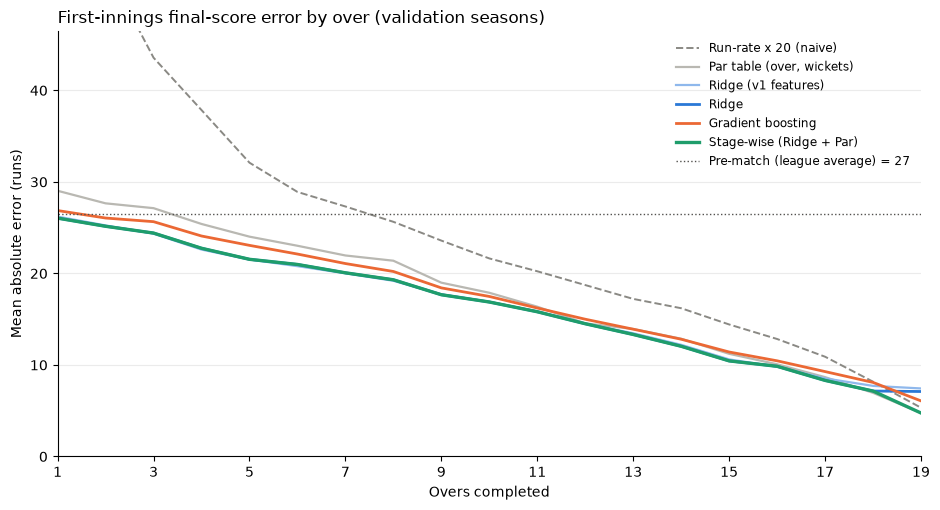

In [16]:
# ---- chart: MAE falls as the innings reveals itself ----
GRAY, GRAY2, BLUE, LBLUE, ORANGE, GREEN = "#8a8984", "#b9b8b2", "#2a78d6", "#8fb8ec", "#eb6834", "#1f9d6b"
style = {
    NAIVE:    dict(color=GRAY,   ls="--", lw=1.4),
    PAR:      dict(color=GRAY2,  ls="-",  lw=1.6),
    RIDGE_V1: dict(color=LBLUE,  ls="-",  lw=1.6),
    RIDGE:    dict(color=BLUE,   ls="-",  lw=2.0),
    GB:       dict(color=ORANGE, ls="-",  lw=2.0),
    STAGE:    dict(color=GREEN,  ls="-",  lw=2.4),
}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for name, st in style.items():
    if name in by_over:
        ax.plot(by_over.index, by_over[name], label=name, **st)
ax.axhline(pre_mae, color="#52514e", lw=1, ls=":", label="Pre-match (league average) = %.0f" % pre_mae)
model_cols = [c for c in by_over.columns if c != NAIVE]
ax.set_ylim(0, max(by_over[model_cols].max().max(), pre_mae) * 1.6)     # naive is huge early; clip so real models stay readable
ax.legend(frameon=False, loc="upper right", fontsize=8.5)
ax.set_xlabel("Overs completed")
ax.set_ylabel("Mean absolute error (runs)")
ax.set_title("First-innings final-score error by over (validation seasons)", loc="left")
ax.set_xlim(1, 19)
ax.set_xticks(range(1, 20, 2))
ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "live_first_innings_mae_by_over.png", dpi=150)
plt.show()

## 6. Honest ranges: 80% prediction interval (v3: width scale chosen on validation)
Method (unchanged from v2): for each of the last N seasons before the target season, fit the point model on everything older
and record its signed errors on that season; per over (+-1 over smoothing) take the 10th/90th percentile of those errors;
add them to a point model trained on all earlier seasons.

v3 adds one knob, `scale`: the range is `mid + scale * q10` ... `mid + scale * q90`.
We try N = 1, 2, 3 calibration seasons and scales 1.00-1.50 **on validation folds only**, then keep the *narrowest* setting whose pooled
coverage reaches 80%. A range that is narrower but misses its promise is worse than a wider honest one.

In [17]:
champion = overall.index[0]
POINT_MODEL = {M.name: M for M in MODELS}[champion]
print("Point model used for ranges:", POINT_MODEL.name)


class CalibratedRange:
    def __init__(self, point_cls, n_calib=2, scale=1.0, lo_q=0.10, hi_q=0.90):
        self.point_cls, self.n_calib, self.scale, self.lo_q, self.hi_q = point_cls, n_calib, scale, lo_q, hi_q

    def fit(self, data):
        # data = every snapshot row available for training (seasons strictly before the target season)
        seasons = sorted(data["season"].unique())
        errs, overs = [], []
        for s in seasons[-self.n_calib:]:
            tr, va = data[data["season"] < s], data[data["season"] == s]
            if len(tr) == 0 or len(va) == 0:
                continue
            p = self.point_cls().fit(tr)
            errs.append((va["final_score"] - p.predict_final(va)).to_numpy())
            overs.append(va["over"].to_numpy())
        if not errs:
            raise ValueError("Not enough history to calibrate a range")
        err, ov = np.concatenate(errs), np.concatenate(overs)
        self.q = {}
        for k in range(1, TOTAL_OVERS):
            near = np.abs(ov - k) <= 1
            e = err[near] if near.sum() >= 30 else err
            self.q[k] = (np.quantile(e, self.lo_q), np.quantile(e, self.hi_q))
        self.pt = self.point_cls().fit(data)
        return self

    def predict(self, df):
        mid = self.pt.predict_final(df)
        lo = mid + self.scale * np.array([self.q[k][0] for k in df["over"]])
        hi = mid + self.scale * np.array([self.q[k][1] for k in df["over"]])
        return lo, mid, hi


def interval_eval(n_calib):
    rows = []
    for f in FOLDS:
        data = dev[dev["season"] <= f["train_through"]]
        va = dev[dev["season"] == f["validate"]]
        if len(data) == 0:
            continue
        lo, mid, hi = CalibratedRange(POINT_MODEL, n_calib).fit(data).predict(va)
        rows.append(va[["match_id", "season", "over", "final_score"]].assign(lo=lo, mid=mid, hi=hi))
    return pd.concat(rows)


def rescale(iv, s):
    out = iv.copy()
    out["lo"] = iv["mid"] + s * (iv["lo"] - iv["mid"])
    out["hi"] = iv["mid"] + s * (iv["hi"] - iv["mid"])
    out["covered"] = (out["final_score"] >= out["lo"]) & (out["final_score"] <= out["hi"])
    out["width"] = out["hi"] - out["lo"]
    return out


def coverage_table(iv, overs=CHECKPOINTS):
    g = iv[iv["over"].isin(overs)].groupby("over")
    t = g.agg(coverage=("covered", "mean"), avg_range_width=("width", "mean"), n=("covered", "size"))
    t["+-95% (sampling)"] = 1.96 * np.sqrt(t["coverage"] * (1 - t["coverage"]) / t["n"])
    return t


iv_raw = {n: interval_eval(n) for n in (1, 2, 3)}
SCALES = [round(x, 2) for x in np.arange(1.0, 1.501, 0.05)]
grid = []
for n, iv in iv_raw.items():
    for s in SCALES:
        r = rescale(iv, s)
        grid.append(dict(n_calib=n, scale=s, pooled_coverage=r["covered"].mean(), avg_width=r["width"].mean()))
grid = pd.DataFrame(grid)

print("Pooled validation coverage / average width (all overs) by calibration seasons and width scale:")
display(grid[grid["scale"].isin([1.0, 1.1, 1.2, 1.3, 1.4])].round(3).set_index(["n_calib", "scale"]))

ok = grid[grid["pooled_coverage"] >= 0.80]
pick = (ok.sort_values("avg_width").iloc[0] if len(ok)
        else grid.sort_values("pooled_coverage", ascending=False).iloc[0])
CHOSEN_N, CHOSEN_SCALE = int(pick["n_calib"]), float(pick["scale"])
print("\nChosen on validation only: n_calib = %d, scale = %.2f (pooled coverage %.3f, avg width %.1f)%s" % (
    CHOSEN_N, CHOSEN_SCALE, pick["pooled_coverage"], pick["avg_width"],
    "" if len(ok) else "  <- no setting reached 80%; widest-coverage setting used"))

chosen = rescale(iv_raw[CHOSEN_N], CHOSEN_SCALE)
print("\nCoverage by over with the chosen setting (validation):")
display(coverage_table(chosen).round(2))
print("Coverage by validation season (is it stable, or driven by one season?):")
display(chosen.groupby("season")["covered"].mean().round(3).to_frame("coverage"))

Point model used for ranges: Stage-wise (Ridge + Par)
Pooled validation coverage / average width (all overs) by calibration seasons and width scale:


pooled_coverage  avg_width
n_calib scale                            
1       1.0              0.767     49.517
        1.1              0.808     54.469
        1.2              0.845     59.421
        1.3              0.876     64.372
        1.4              0.897     69.324
2       1.0              0.780     50.242
        1.1              0.823     55.267
        1.2              0.860     60.291
        1.3              0.892     65.315
        1.4              0.914     70.339
3       1.0              0.788     50.384
        1.1              0.829     55.423
        1.2              0.865     60.461
        1.3              0.896     65.500
        1.4              0.919     70.538


Chosen on validation only: n_calib = 2, scale = 1.05 (pooled coverage 0.802, avg width 52.8)

Coverage by over with the chosen setting (validation):


,coverage,avg_range_width,n,+-95% (sampling)
over,,,,
1,0.78,78.34,349,0.04
3,0.77,73.96,349,0.04
6,0.77,67.24,349,0.04
10,0.78,53.02,349,0.04
15,0.83,37.32,348,0.04
18,0.80,23.62,342,0.04


Coverage by validation season (is it stable, or driven by one season?):


,coverage
season,
2021,0.746
2022,0.847
2023,0.805
2024,0.787
2025,0.813


## 7. Final holdout (2026) - evaluated once
Everything below is computed a single time. Do not re-run it with changed settings to chase a better number -
that turns the holdout into another validation set.

Only one season is left, so the sample is small (see `n_matches`). Wide confidence intervals are expected and are the honest answer.

In [18]:
print("Champion chosen on validation folds only:", champion)
print("Holdout matches:", holdout["match_id"].nunique(), "(small sample - read the CIs)")

if len(holdout):
    final_models = [M().fit(dev) for M in MODELS]
    hp = pd.concat([
        holdout[["match_id", "over", "final_score"]].assign(
            model=m.name, pred=m.predict_final(holdout)) for m in final_models], ignore_index=True)
    hp["abs_err"] = (hp["pred"] - hp["final_score"]).abs()
    holdout_tbl = hp.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
    print("\nHoldout MAE by over (2026):")
    display(holdout_tbl.loc[[o for o in CHECKPOINTS if o in holdout_tbl.index]].round(1))
    holdout_tbl.to_csv(REPORTS_DIR / "live_first_innings_holdout_mae.csv")

    print("Mean MAE over overs 1-19:")
    print(hp.groupby("model")["abs_err"].mean().sort_values().round(2).to_string())

    print("\nBootstrap comparisons on the holdout:")
    holdout_compare = compare(hp, matches[matches["season"] >= HOLDOUT_START])
    show_compare(holdout_compare)
    holdout_compare.to_csv(REPORTS_DIR / "live_first_innings_holdout_bootstrap.csv", index=False)

    # interval coverage on the holdout: settings chosen on validation, applied once
    lo, mid, hi = CalibratedRange(POINT_MODEL, CHOSEN_N, CHOSEN_SCALE).fit(dev).predict(holdout)
    hv = holdout[["over", "final_score"]].assign(lo=lo, mid=mid, hi=hi)
    hv["covered"] = (hv["final_score"] >= hv["lo"]) & (hv["final_score"] <= hv["hi"])
    hv["width"] = hv["hi"] - hv["lo"]
    print("\nHoldout 80%% range coverage: pooled %.3f" % hv["covered"].mean())
    display(coverage_table(hv).round(2))
else:
    print("No 2025+ matches in the data - holdout skipped.")

by_over.round(3).to_csv(REPORTS_DIR / "live_first_innings_validation_mae_by_over.csv")
dev_compare.to_csv(REPORTS_DIR / "live_first_innings_validation_bootstrap.csv", index=False)

Champion chosen on validation folds only: Stage-wise (Ridge + Par)
Holdout matches: 71 (small sample - read the CIs)

Holdout MAE by over (2026):


model,Gradient boosting,"Par table (over, wickets)",Ridge,Ridge (v1 features),Run-rate x 20 (naive),Stage-wise (Ridge + Par)
over,,,,,,
1,32.0,35.6,28.8,29.1,74.8,28.8
3,28.6,32.5,25.0,25.1,45.0,25.0
6,22.6,25.7,21.0,21.2,35.1,21.0
10,18.9,19.3,17.7,17.7,24.0,17.7
15,13.0,12.1,12.5,12.3,13.3,12.5
18,8.3,7.3,10.3,11.8,8.1,10.3


Mean MAE over overs 1-19:
model
Stage-wise (Ridge + Par)     17.59
Ridge                        17.81
Ridge (v1 features)          18.05
Gradient boosting            18.92
Par table (over, wickets)    19.87
Run-rate x 20 (naive)        27.40

Bootstrap comparisons on the holdout:

Ridge  vs  Ridge (v1 features)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,71,0.33,-0.11,0.81,noise
3,71,0.11,-0.38,0.66,noise
6,71,0.11,-0.81,0.98,noise
10,71,-0.04,-0.43,0.34,noise
15,71,-0.27,-0.85,0.33,noise
18,70,1.52,0.82,2.23,challenger better
ALL,71,0.25,-0.03,0.54,noise



Stage-wise (Ridge + Par)  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,71,0.00,0.00,0.00,noise
3,71,0.00,0.00,0.00,noise
6,71,0.00,0.00,0.00,noise
10,71,0.00,0.00,0.00,noise
15,71,0.00,0.00,0.00,noise
18,70,0.00,0.00,0.00,noise
ALL,71,0.22,0.14,0.29,challenger better


... (4 outputs left out)


Ridge  vs  Pre-match (league avg)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,71,1.41,-1.09,3.84,noise
3,71,5.20,1.42,9.04,challenger better
6,71,9.18,4.44,14.02,challenger better
10,71,12.53,7.78,17.17,challenger better
15,71,17.69,12.33,22.75,challenger better
18,70,18.62,14.41,22.79,challenger better
ALL,71,12.35,8.25,16.29,challenger better



Holdout 80% range coverage: pooled 0.762


,coverage,avg_range_width,n,+-95% (sampling)
over,,,,
1,0.76,81.03,71,0.10
3,0.76,78.09,71,0.10
6,0.86,74.04,71,0.08
10,0.80,56.90,71,0.09
15,0.69,35.70,71,0.11
18,0.53,21.67,70,0.12


## 8. Use it: predict a live innings
Pass the **cumulative** score after each completed over (runs, wickets, boundaries) and the venue.
The venue effect and league average are computed from all matches in the data.

In [19]:
# Final model for real use: the holdout has been evaluated, so now train on ALL data and calibrate on the latest seasons
full_interval = CalibratedRange(POINT_MODEL, CHOSEN_N, CHOSEN_SCALE).fit(snap)


def current_context(venue_name, league_window=60, venue_shrink=5.0):
    league = matches["final_score"].to_numpy()[-league_window:].mean()       # matches are sorted by date
    sub = matches[matches["venue"] == standardize_venue(venue_name)]
    n = len(sub)
    return dict(league_recent=league,
                venue_effect=sub["excess"].sum() / (n + venue_shrink),
                venue_prior=(sub["final_score"].sum() + venue_shrink * league) / (n + venue_shrink),
                venue_n=n)


def predict_live(cum_runs, cum_wickets, cum_boundaries, venue):
    k = len(cum_runs)
    assert 1 <= k <= 19 and len(cum_wickets) == k and len(cum_boundaries) == k
    states = {i + 1: (cum_runs[i], cum_wickets[i], cum_boundaries[i]) for i in range(k)}
    row = snapshot_features(states, k)
    row.update(current_context(venue))
    row = add_linear_terms(pd.DataFrame([row]))
    lo, mid, hi = full_interval.predict(row)
    return round(float(mid[0])), round(float(lo[0])), round(float(hi[0]))


# Example: 10 overs done, 92/2, the last five overs gave 54
runs_by_over = [7, 15, 24, 31, 38, 50, 58, 68, 79, 92]
wkts_by_over = [0, 0, 0, 1, 1, 1, 1, 2, 2, 2]
bnd_by_over  = [1, 2, 3, 4, 5, 7, 8, 9, 10, 12]
mid, lo, hi = predict_live(runs_by_over, wkts_by_over, bnd_by_over, venue="Wankhede Stadium")
print("Projected total: %d  (80%% range %d - %d)" % (mid, lo, hi))

Projected total: 202  (80% range 171 - 232)


## Export for the dashboard
Writes `nb03.json` into `dashboard/public/data/` (override with the `IPL_DASHBOARD_DATA` environment variable). The React dashboard reads these files.
This cell only reads results that are already in memory, so run it **after** the cells above.

In [21]:
# ===== Dashboard export =====================================================================
# Writes JSON files that the React dashboard reads. Safe to re-run; it only writes files.
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)


def _clean(x):
    if isinstance(x, dict):
        return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v) for v in x]
    if isinstance(x, pd.DataFrame):
        return _clean(x.reset_index().to_dict("records"))
    if isinstance(x, pd.Series):
        return _clean(x.to_dict())
    if isinstance(x, np.ndarray):
        return _clean(x.tolist())
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return round(float(x), 5) if np.isfinite(x) else None
    if isinstance(x, (pd.Timestamp, datetime.date)):
        return str(x)[:10]
    if x is None or isinstance(x, str):
        return x
    return str(x)


def tbl(df, scale=1.0):
    # pivot-style table -> {"index": [...], "columns": [...], "data": [[...]]}
    d = df.astype(float) * scale
    return {"index": _clean(list(d.index)), "columns": [str(c) for c in d.columns], "data": _clean(d.values.tolist())}


def recs(df):
    d = df.copy()
    for c in d.columns:
        if str(d[c].dtype).startswith("category") or d[c].dtype == object:
            d[c] = d[c].astype(str)
    return _clean(d.reset_index(drop=True).to_dict("records"))


def dash_save(name, payload):
    meta = {"notebook": name, "generated": datetime.datetime.now().isoformat(timespec="seconds"),
            "matches": int(len(matches)), "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())}
    path = DASH_DIR / (name + ".json")
    path.write_text(json.dumps(_clean({"meta": meta, **payload}), separators=(",", ":")), encoding="utf-8")
    print("wrote %s (%.0f KB)" % (path, path.stat().st_size / 1024))

payload = {
    "champion": str(champion), "best_model": str(best_name),
    "mae_by_over": tbl(by_over),                                         # validation MAE, all overs x models
    "compare_validation": recs(dev_compare),
    "pre_match_mae": {k: float(v.mean()) for k, v in pre_err.items()},
    "interval": {"n_calib": int(CHOSEN_N), "scale": float(CHOSEN_SCALE), "grid": recs(grid),
                 "coverage_validation": recs(coverage_table(chosen).rename_axis("over").reset_index()), "by_season": recs(chosen.groupby("season")["covered"].mean().to_frame("coverage").reset_index())},
}
if "holdout_tbl" in globals():
    payload["mae_holdout"] = tbl(holdout_tbl)
    payload["compare_holdout"] = recs(holdout_compare)
    payload["interval"]["coverage_holdout"] = recs(coverage_table(hv).rename_axis("over").reset_index())
chk_ = chosen.merge(dev[["match_id", "over", "wickets"]], on=["match_id", "over"])
chk_["wk_bucket"] = pd.cut(chk_["wickets"], [-1, 2, 4, 6, 10], labels=["0-2", "3-4", "5-6", "7+"])
chk_["bias"] = chk_["mid"] - chk_["final_score"]
payload["by_wickets"] = recs(chk_.groupby("wk_bucket", observed=True).agg(rows=("covered", "size"), coverage=("covered", "mean"), bias=("bias", "mean"), avg_width=("width", "mean")).reset_index())

# ===== Historical match-level predictions for Score Engine 2.0 =====

# Validation predictions: chosen contains out-of-fold predictions
history_val = chosen[
    ["match_id", "season", "over", "final_score", "lo", "mid", "hi"]
].copy()

# Holdout predictions: model trained only on development data
history_parts = [history_val]

if len(holdout):
    h_lo, h_mid, h_hi = CalibratedRange(
        POINT_MODEL, CHOSEN_N, CHOSEN_SCALE
    ).fit(dev).predict(holdout)

    history_holdout = holdout[
        ["match_id", "season", "over", "final_score"]
    ].copy()

    history_holdout["lo"] = h_lo
    history_holdout["mid"] = h_mid
    history_holdout["hi"] = h_hi

    history_parts.append(history_holdout)

history_predictions = pd.concat(history_parts, ignore_index=True)

# Match metadata
history_meta = matches[
    ["match_id", "date", "season", "venue", "batting_team"]
].copy()

# Actual cumulative score at the end of each over
state_rows = []

for match_id, states in states_by_match.items():
    for over, (runs, wickets, boundaries) in states.items():
        if 1 <= over <= 19:
            state_rows.append({
                "match_id": match_id,
                "over": over,
                "runs": runs,
                "wickets": wickets,
                "boundaries": boundaries
            })

history_states = pd.DataFrame(state_rows)

# Join actual match states with honest model predictions
history = (
    history_predictions
    .merge(history_meta, on="match_id", how="inner")
    .merge(history_states, on=["match_id", "over"], how="inner")
    .sort_values(["date", "match_id", "over"])
)

# Export compact match-level records
payload["match_history"] = recs(history)

print(
    "Historical match records:",
    history["match_id"].nunique(),
    "| over-level prediction rows:",
    len(history)
)

dash_save("nb03", payload)


Historical match records: 420 | over-level prediction rows: 7950
wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\nb03.json (2034 KB)


In [22]:
# ===== Per-match export for the dashboard (paste as a NEW LAST CELL) ========================
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)
OVERS = list(range(1, 20))                                   # overs 1..19 (the over-20 state is the final score)


def pack_by_match(df, col, nd=3):
    # one list of 19 numbers per match (index 0 = over 1); None where that over has no row
    piv = df.pivot_table(index="match_id", columns="over", values=col, aggfunc="first").reindex(columns=OVERS)
    return {str(mid): [None if pd.isna(v) else round(float(v), nd) for v in row] for mid, row in zip(piv.index, piv.values)}


def merge_save(file, section, payload):
    # predictions.json is shared by notebooks 03, 04 and 06: each one only replaces its own section
    path = DASH_DIR / (file + ".json")
    cur = {}
    if path.exists():
        try:
            cur = json.loads(path.read_text(encoding="utf-8"))
        except Exception:
            cur = {}
    meta = cur.get("meta", {})
    meta.update({"generated": datetime.datetime.now().isoformat(timespec="seconds"), "matches": int(len(matches)),
                 "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())})
    cur["meta"] = meta
    cur[section] = payload
    meta["sections"] = sorted(k for k in cur if k != "meta")
    path.write_text(json.dumps(cur, separators=(",", ":")), encoding="utf-8")
    print("wrote %s section '%s' (file now %.0f KB)" % (path, section, path.stat().st_size / 1024))

# Out-of-sample champion projection + 80% range for every validation (2021-25) and holdout (2026) match.
_cols = ["match_id", "over", "lo", "mid", "hi"]
_parts, _split = [chosen[_cols]], {str(m): "val" for m in chosen["match_id"].unique()}
if "hv" in globals():
    _h = hv.assign(match_id=holdout.loc[hv.index, "match_id"].to_numpy())[_cols]
    _parts.append(_h)
    _split.update({str(m): "hold" for m in _h["match_id"].unique()})
_all = pd.concat(_parts, ignore_index=True)
_pk = {c: pack_by_match(_all, c, nd=1) for c in ("mid", "lo", "hi")}
merge_save("predictions", "nb03", {
    "model": str(champion), "interval": {"n_calib": int(CHOSEN_N), "scale": float(CHOSEN_SCALE), "nominal": 0.8},
    "overs": OVERS,
    "matches": {m: {"split": s, "pred": _pk["mid"][m], "lo": _pk["lo"][m], "hi": _pk["hi"][m]} for m, s in _split.items()},
})

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\predictions.json section 'nb03' (file now 161 KB)
